In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import (
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    pipeline, DataCollatorForSeq2Seq, EarlyStoppingCallback
)
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from safetensors.torch import load_file

In [2]:
# Read the CSV file
data = pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/bible.csv")
extra_data=pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/Nagamese Khobor Comic and Other Resouces.csv")

In [3]:
print("Bible dataset:", len(data))
print("Non-Bible dataset:", len(extra_data))

Bible dataset: 7950
Non-Bible dataset: 821


In [4]:
# Load model and tokenizer
model_name = "facebook/mbart-large-50-many-to-many-mmt"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.44G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/261 [00:00<?, ?B/s]

In [5]:
data["source"] = "Bible"
extra_data["source"] = "Non-Bible"

df = pd.concat([data, extra_data], ignore_index=True)
df = df.dropna(subset=["English", "Nagamese"])
df = df.drop_duplicates(subset=["English", "Nagamese"])
# df = df.head(10)

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=61
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=61
)

# Prepare text lists
train_source_texts = train_df["English"].tolist()
train_target_texts = train_df["Nagamese"].tolist()

val_source_texts = val_df["English"].tolist()
val_target_texts = val_df["Nagamese"].tolist()

test_source_texts = test_df["English"].tolist()
test_target_texts = test_df["Nagamese"].tolist()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 7014
Validation samples: 877
Testing samples: 877


In [6]:
import random
random.seed(7)
# Combine and shuffle the training data
combined_train = list(zip(train_source_texts, train_target_texts))
random.shuffle(combined_train)

# Unzip back into separate lists
train_source_texts, train_target_texts = zip(*combined_train)
train_source_texts = list(train_source_texts)
train_target_texts = list(train_target_texts)

In [7]:
from datasets import Dataset

# Tokenize function
def tokenize_function(examples):
    model_inputs = tokenizer(examples["source_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")
    labels = tokenizer(examples["target_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")["input_ids"]
    # labels = [[-100 if token == tokenizer.pad_token_id else token for token in label] for label in labels]
    model_inputs["labels"]=labels
    return model_inputs

# Convert lists to Hugging Face Dataset
train_dataset = Dataset.from_dict({"source_texts": train_source_texts, "target_texts": train_target_texts})
val_dataset = Dataset.from_dict({"source_texts": val_source_texts, "target_texts": val_target_texts})

# Tokenize datasets
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])



Map:   0%|          | 0/7014 [00:00<?, ? examples/s]

Map:   0%|          | 0/877 [00:00<?, ? examples/s]

In [8]:
print(train_dataset["input_ids"][0])
print(train_dataset["input_ids"][1])

print(train_dataset["labels"][0])
print(train_dataset["labels"][1])

[250004, 31384, 3395, 3542, 15756, 34, 1916, 1632, 13580, 4, 136, 3060, 15700, 4, 100, 70, 131126, 509, 23, 169463, 5, 17006, 111, 2856, 6777, 959, 3853, 3714, 15400, 1836, 1902, 1380, 25842, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[250004, 1529, 17378, 4, 44, 571, 9393, 297, 621, 8382, 124901, 27165, 9393, 8, 297, 7, 621, 100, 107409, 4, 136, 124901, 880, 7, 621, 127918, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[250004, 1172, 34, 15926, 42, 120, 3319, 161, 949, 402, 196, 11, 200, 402,

In [9]:
!pip install sacrebleu
import sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 5.8 MB/s eta 0:00:00


In [10]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)

    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)

    predictions = predictions.astype(np.int64)
    
    # ✅ Fix: clip to valid vocab range and replace negatives with pad token
    vocab_size = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size - 1)

    labels = np.where(
        labels == -100,
        tokenizer.pad_token_id,
        labels
    ).astype(np.int64)
    labels = np.clip(labels, 0, vocab_size - 1)  # ✅ also clip labels

    decoded_preds = tokenizer.batch_decode(predictions.tolist(), skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels.tolist(), skip_special_tokens=True)

    decoded_preds = [x.strip() for x in decoded_preds]
    decoded_labels = [x.strip() for x in decoded_labels]

    bleu = sacrebleu.corpus_bleu(decoded_preds, [decoded_labels])
    ter = sacrebleu.corpus_ter(decoded_preds, [decoded_labels])
    chrf = sacrebleu.corpus_chrf(decoded_preds, [decoded_labels])

    return {"bleu": bleu.score, "ter": ter.score, "chrf": chrf.score}

In [11]:
# Training Arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./results",
    logging_strategy="epoch", 
    eval_strategy="epoch", 
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_ratio=0.1,
    seed = 40,
    save_total_limit=2,
    num_train_epochs=10,
    predict_with_generate=True,
    optim="adafactor", 
    report_to=[],
    fp16=True,
    logging_dir="./logs",
    # overwrite_output_dir=True,
    load_best_model_at_end=True,
    disable_tqdm=True
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=1)],
    compute_metrics=compute_metrics,
)

# Start Training
trainer.train()


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


{'loss': '2.622', 'grad_norm': '1.953', 'learning_rate': '4.971e-05', 'epoch': '1'}
{'eval_loss': '0.6318', 'eval_bleu': '16.47', 'eval_ter': '73.55', 'eval_chrf': '46.48', 'eval_runtime': '225.6', 'eval_samples_per_second': '3.887', 'eval_steps_per_second': '0.244', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.5274', 'grad_norm': '1.51', 'learning_rate': '4.448e-05', 'epoch': '2'}
{'eval_loss': '0.4999', 'eval_bleu': '20.76', 'eval_ter': '67.08', 'eval_chrf': '52', 'eval_runtime': '232.8', 'eval_samples_per_second': '3.767', 'eval_steps_per_second': '0.236', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

{'loss': '0.2675', 'grad_norm': '1.816', 'learning_rate': '3.337e-05', 'epoch': '4'}
{'eval_loss': '0.4993', 'eval_bleu': '22.78', 'eval_ter': '65.07', 'eval_chrf': '53.79', 'eval_runtime': '230.9', 'eval_samples_per_second': '3.798', 'eval_steps_per_second': '0.238', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


{'train_runtime': '3433', 'train_samples_per_second': '20.43', 'train_steps_per_second': '2.555', 'train_loss': '0.9471', 'epoch': '4'}


TrainOutput(global_step=3508, training_loss=0.9470577218241675, metrics={'train_runtime': 3432.5753, 'train_samples_per_second': 20.434, 'train_steps_per_second': 2.555, 'train_loss': 0.9470577218241675, 'epoch': 4.0})

In [12]:
model.save_pretrained("./nllb_model")
tokenizer.save_pretrained("./nllb_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./nllb_model/tokenizer_config.json', './nllb_model/tokenizer.json')

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "./nllb_model",
    attn_implementation="eager"
).to(device)
model.eval()

Using device: cuda


Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

MBartForConditionalGeneration(
  (model): MBartModel(
    (shared): MBartScaledWordEmbedding(250054, 1024, padding_idx=1)
    (encoder): MBartEncoder(
      (embed_tokens): MBartScaledWordEmbedding(250054, 1024, padding_idx=1)
      (embed_positions): MBartLearnedPositionalEmbedding(1026, 1024)
      (layers): ModuleList(
        (0-11): 12 x MBartEncoderLayer(
          (self_attn): MBartAttention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): ReLU()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        

In [14]:
source_texts = val_source_texts
reference_texts = val_target_texts

In [15]:
# Translate source texts using the model
model.eval()
machine_translations = []
batch_size=32
for i in range(0, len(source_texts), batch_size):
    batch_texts = source_texts[i : i + batch_size]  # Slice batch
    inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    with torch.no_grad():
        outputs = model.generate(**inputs)
    
    batch_translations = tokenizer.batch_decode(outputs, skip_special_tokens=True)
    machine_translations.extend(batch_translations)

In [16]:
wrapped_reference_texts = [reference_texts] 
bleu = sacrebleu.corpus_bleu(machine_translations, wrapped_reference_texts)
print("BLEU Score:", bleu.score)
ter = sacrebleu.corpus_ter(machine_translations, wrapped_reference_texts)
print("TER Score:", ter.score)
chrf = sacrebleu.corpus_chrf(machine_translations, wrapped_reference_texts)
print("CHRF Score:", chrf.score)

BLEU Score: 22.51702791039391
TER Score: 65.48218435321456
CHRF Score: 53.83308604394003


In [17]:
n = 31
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: He is staying with a tanner named Simon, whose house is by the seaside."
Translated: Tai tanner Simon koi kena thaki ase, tai laga ghor samundar kinar te thaki ase.”
Reference: Tai Simon koi kena ekjon chamra ula kaam kora manu laga ghor te ase, tai laga ghor samundar kinar te ase.”


In [18]:
n = 81
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Those who were leading Paul took him as far as the city of Athens. As they left Paul there, they received from him instructions for Silas and Timothy to come to him as quickly as possible.
Translated: Aru Paul ke chola bole thaka khan pora Athens te loi jaise. Aru jitia Paul ke tate loi jaise, tai pora Silas aru Timothy ke tai logote joldi ahibole koise.
Reference: Aru jun manu Paul ke loi jaise tai khan Athens laga sheher pora aru dur te taike loi jaise. Aru jitia tai khan Silas aru Timothy duijon ke Paul pora tai usorte te joldi ahibole dibi koi kena khobor paise, tai khan nijor laga ghor te jai jaise.


In [19]:
n = 22
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: having the same conflict which you saw in me, and now you hear in me.
Translated: Itu karone apnikhan Moi logote lorai kori thakise, aru etiya to apnikhan Moi logote hunise.
Reference: apni khan dikhise moi ki logote lorai kori ase, aru etiya apni khan moi pora itu khan sob huni ase.


Input:      So Paul reasoned in the synagogue every Sabbath, trying to persuade both Jews and Greeks.
Translated: Aru hodai Bisram din te Paul mondoli te bhabona kori thakise, aru Yehudi aru Yunani khan ke kotha koi thakise.
Reference:  Aru Paul to mondoli te jai kena hodai Bisram din te tai khan logote kotha kori thakise. Tai Yehudi aru Yunani manu khan ke Isor laga kotha mani kena thakibole nimite koi thakise.


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

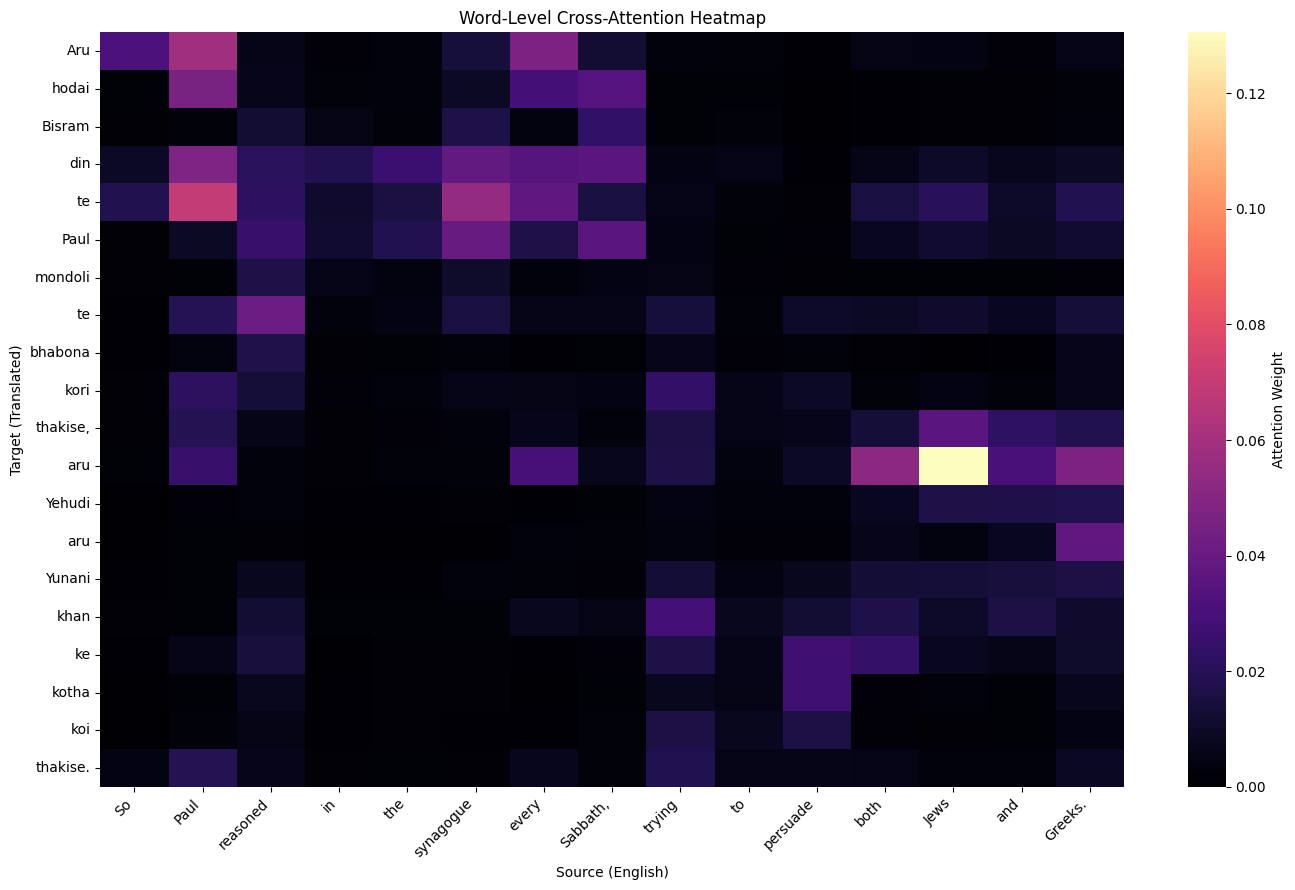


🔗 Word Alignments:

Target Word               →  Source Word
---------------------------------------------
Aru                       →  Paul
hodai                     →  Paul
Bisram                    →  Sabbath,
din                       →  Paul
te                        →  Paul
Paul                      →  synagogue
mondoli                   →  reasoned
te                        →  reasoned
bhabona                   →  reasoned
kori                      →  trying
thakise,                  →  Jews
aru                       →  Jews
Yehudi                    →  Greeks.
aru                       →  Greeks.
Yunani                    →  Greeks.
khan                      →  trying
ke                        →  persuade
kotha                     →  persuade
koi                       →  trying
thakise.                  →  Paul


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np

def merge_sentencepiece_tokens(tokens):
    words = []
    current_word = ""
    mapping = []
    word_idx = -1

    for i, tok in enumerate(tokens):
        if tok.startswith("▁") or tok.startswith("_"):  # SentencePiece or underscore-prefix
            if current_word:
                words.append(current_word)
            current_word = tok[1:]  # remove prefix
            word_idx += 1
        else:
            current_word += tok
        mapping.append(word_idx)
    if current_word:
        words.append(current_word)
    return words, mapping

def aggregate_attention(attn_matrix, src_map, tgt_map):
    num_tgt_words = max(tgt_map) + 1
    num_src_words = max(src_map) + 1
    agg_matrix = np.zeros((num_tgt_words, num_src_words))
    count_matrix = np.zeros((num_tgt_words, num_src_words))

    for i_tgt, tgt_word_idx in enumerate(tgt_map):
        for i_src, src_word_idx in enumerate(src_map):
            agg_matrix[tgt_word_idx][src_word_idx] += attn_matrix[i_tgt][i_src]
            count_matrix[tgt_word_idx][src_word_idx] += 1

    # Avoid division by zero
    count_matrix[count_matrix == 0] = 1
    return agg_matrix / count_matrix

# ----------------------------
# Your original pipeline
# ----------------------------
n = 28
tokenizer.src_lang = "en_XX"
tokenizer.tgt_lang = "en_XX"

inputs = tokenizer(
    source_texts[n], return_tensors="pt",
    max_length=128, truncation=True
).to(device)

with torch.no_grad():
    generated = model.generate(
        **inputs,
        max_length=128
    )

translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)
print(f"Input:      {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference:  {reference_texts[n]}")

decoder_input_ids = generated[:, :-1]

with torch.no_grad():
    out = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )

cross_attn_avg = out.cross_attentions[-1][0].mean(dim=0)  # [tgt_len, src_len]

# ── Token filtering ───────────────────────────────────────────────
special_ids = set(tokenizer.all_special_ids)

src_token_ids = inputs["input_ids"][0].tolist()
tgt_token_ids = decoder_input_ids[0].tolist()

# Build index maps: only keep non-special tokens, track their positions
src_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(src_token_ids) if tid not in special_ids]
tgt_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(tgt_token_ids) if tid not in special_ids]

src_indices, src_tokens_clean = zip(*src_keep) if src_keep else ([], [])
tgt_indices, tgt_tokens_clean = zip(*tgt_keep) if tgt_keep else ([], [])

src_indices = list(src_indices)
tgt_indices = list(tgt_indices)
src_tokens_clean = list(src_tokens_clean)
tgt_tokens_clean = list(tgt_tokens_clean)

# ── Slice attention to only non-special token positions ───────────
attn_np = cross_attn_avg.cpu().numpy()
attn_filtered = attn_np[np.ix_(tgt_indices, src_indices)]  # shape: [n_tgt_tokens, n_src_tokens]

# ── Merge subword tokens → words ──────────────────────────────────
src_words, src_map = merge_sentencepiece_tokens(src_tokens_clean)
tgt_words, tgt_map = merge_sentencepiece_tokens(tgt_tokens_clean)

word_attn = aggregate_attention(attn_filtered, src_map, tgt_map)

# ── Font fix for non-Latin scripts ────────────────────────────────
import matplotlib.font_manager as fm
# Use a font that supports Indic scripts if available, else fall back
try:
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSans/NotoSans-Regular.ttf",
        "/tmp/NotoSans-Regular.ttf"
    )
    prop = fm.FontProperties(fname="/tmp/NotoSans-Regular.ttf")
    font_name = prop.get_name()
    plt.rcParams["font.family"] = font_name
except Exception:
    pass  # silently skip if download fails

# ── Plot ──────────────────────────────────────────────────────────
plt.figure(figsize=(14, 9))
sns.heatmap(word_attn,
            xticklabels=src_words,
            yticklabels=tgt_words,
            cmap="magma",
            vmin=0, vmax=word_attn.max(),  # auto-scale vmax
            cbar_kws={"label": "Attention Weight"})
plt.title("Word-Level Cross-Attention Heatmap")
plt.xlabel("Source (English)")
plt.ylabel("Target (Translated)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Alignments ────────────────────────────────────────────────────
print("\n🔗 Word Alignments:\n")
print(f"{'Target Word':<25} →  Source Word")
print("-" * 45)
for tgt_idx, tgt_word in enumerate(tgt_words):
    if tgt_idx >= word_attn.shape[0]:
        break

    if word_attn.shape[1] == 0 or len(src_words) == 0:
        continue

    src_idx = int(np.argmax(word_attn[tgt_idx]))

    if src_idx < len(src_words):
        print(f"{tgt_word:<25} →  {src_words[src_idx]}")